# Give Me Some Credit: EDA

By: Carlos, Alejandro and Gregorio

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/cs-training.csv")
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
# The first column is only the row number added by Kaggle, so we drop it
df = df.drop(columns="Unnamed: 0")
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. Data inspection
We have to understand the structure of the dataset and its variables

In [4]:
df.shape

(150000, 11)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [6]:
# Count the missing values of each column
df.isna().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

The dataset has 150,000 rows and 11 columns, all numeric, so we do not need to encode categories. MonthlyIncome has 29,731 missing values (19.8%) and NumberOfDependents has 3,924 (2.6%). The rest of the columns are complete. We will decide how to fill them in the missing values section, and we will apply it after the train/test split.

In [7]:
# Rows that are exactly the same in all columns
df.duplicated().sum()

np.int64(609)

In [8]:
# Same number as a percentage of the dataset
df.duplicated().sum() / len(df) * 100

np.float64(0.406)

In [9]:
# Show every copy of the duplicated rows, sorted so the identical ones are together
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
dups.head(10)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
134365,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
137102,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
25632,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
83552,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
139345,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
100594,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0
127724,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0
44006,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
54653,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
53012,0,0.0,22,0,0.0,1.0,2,0,0,0,0.0


In [10]:
# Are the duplicates real copies of one row, or simple profiles that many different people share?
# We compare the duplicated rows with the whole dataset
extra_copies = df[df.duplicated()]

print("Duplicated rows:", len(extra_copies))
print("DebtRatio equal to 0 (%):", round((extra_copies["DebtRatio"] == 0).mean() * 100, 1))
print("MonthlyIncome missing or <= 1,000 (%):", round((extra_copies["MonthlyIncome"].isna() | (extra_copies["MonthlyIncome"] <= 1000)).mean() * 100, 1))
print("2 or fewer open credit lines (%): duplicates", round((extra_copies["NumberOfOpenCreditLinesAndLoans"] <= 2).mean() * 100, 1),
      "| whole dataset", round((df["NumberOfOpenCreditLinesAndLoans"] <= 2).mean() * 100, 1))
print("Delinquent customers (%): duplicates", round(extra_copies["SeriousDlqin2yrs"].mean() * 100, 2),
      "| whole dataset", round(df["SeriousDlqin2yrs"].mean() * 100, 2))

Duplicated rows: 609
DebtRatio equal to 0 (%): 98.2
MonthlyIncome missing or <= 1,000 (%): 98.5
2 or fewer open credit lines (%): duplicates 77.3 | whole dataset 8.7
Delinquent customers (%): duplicates 2.79 | whole dataset 6.68


There are 609 duplicated rows (0.41%). The dataset has no customer ID, so we checked what kind of rows they are. Almost all of them are very simple profiles: DebtRatio is 0 in 98% of them, 98.5% have no income or an income of 1,000 or less, and 77% have two or fewer open credit lines (against 8.7% in the whole dataset). Their delinquency rate is also lower (2.79% against 6.68%). They do not look like the same record copied by mistake, but like different people, mostly young customers with almost no credit history, who share the same simple values.

Decision: we keep the duplicated rows. Dropping them would remove real customers of this type, and the effect on the data is very small anyway.

In [11]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


Some values look wrong. age has a minimum of 0, and the late-payment counters have a maximum of 98, far from their usual values. RevolvingUtilizationOfUnsecuredLines should be between 0 and 1, but its maximum is about 50,708. DebtRatio (maximum 329,664) and MonthlyIncome (maximum 3,008,750) also have extreme maximums, and MonthlyIncome has a minimum of 0. We only detect these problems here: the errors will be fixed in the next section and the outliers after that.

### Target distribution
The target variable is SeriousDlqin2yrs: 1 if the customer had a serious delinquency (90 days or more past due) in the next two years, 0 if not

In [12]:
# Number of customers in each class
df["SeriousDlqin2yrs"].value_counts()

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

In [13]:
# Same, as a percentage
df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100

SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64

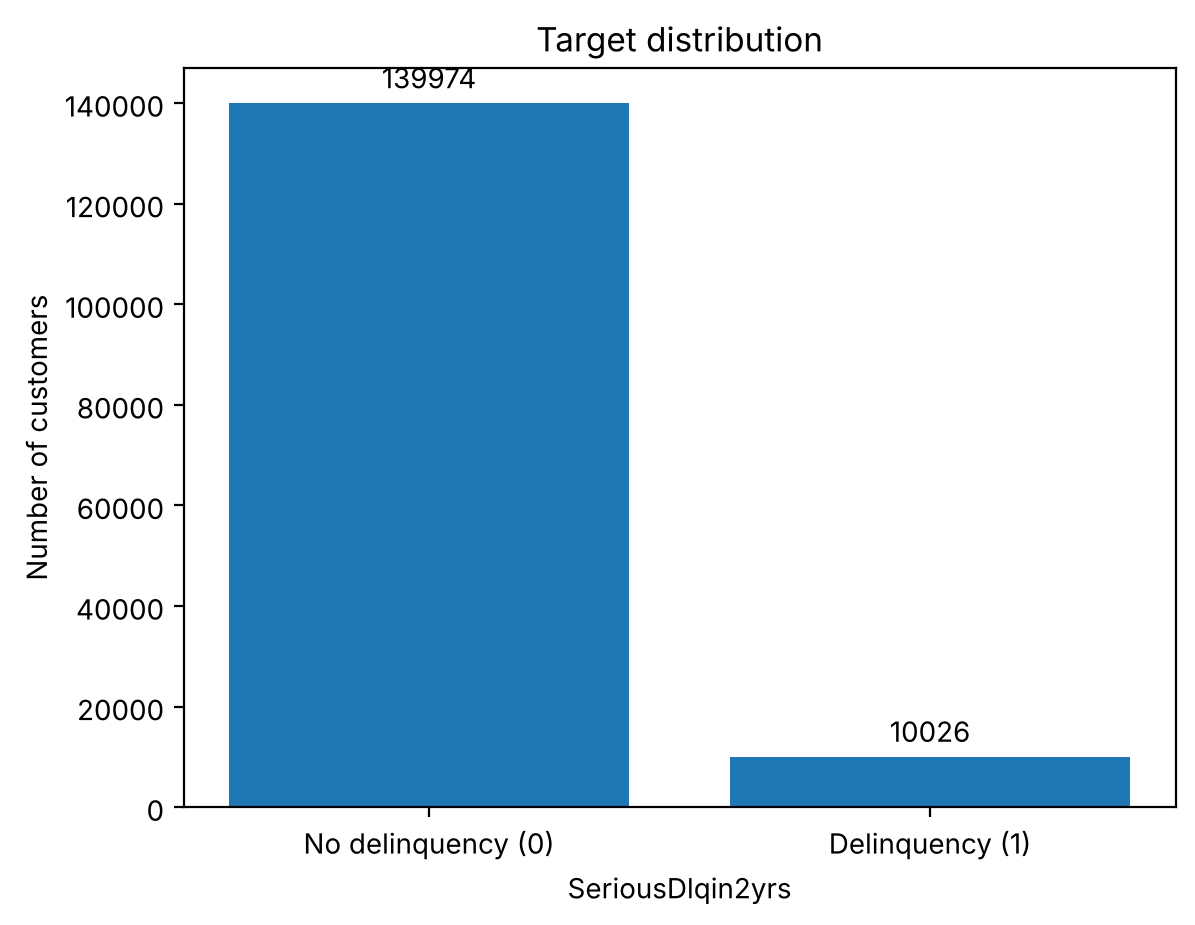

In [14]:
# Bar chart of the two classes
counts = df["SeriousDlqin2yrs"].value_counts()
bars = plt.bar(["No delinquency (0)", "Delinquency (1)"], counts.values)

# Labels with the number of customers on top of each bar
plt.bar_label(bars, padding=3)

plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("Number of customers")
plt.title("Target distribution")
plt.show()

In [15]:
# Accuracy of a "model" that always predicts class 0 (no delinquency)
counts[0] / len(df) * 100

np.float64(93.316)

The target is imbalanced: 10,026 customers (6.68%) had a serious delinquency and 139,974 (93.32%) did not. A model that always predicts "no delinquency" would have 93.3% accuracy and detect no one, so accuracy is not a good metric here. We will use metrics such as ROC-AUC, PR-AUC or recall, and we will split train and test with stratification so both keep the same percentage of delinquent customers.

## 2. Distribution of each variable

The `describe()` above already shows values that do not fit: an age of 0, a maximum of 98 in the three late-payment counters, a `RevolvingUtilizationOfUnsecuredLines` of 50,708 and a `DebtRatio` of 329,664. We add the skewness and the 1st and 99th percentiles. A large gap between the 99th percentile and the maximum points to extreme values or errors.

The imputation and the corrections are decided in these sections but any statistic used to fill a gap (a median, for example) will be computed on the training set only, after the split, so that no information from the test set leaks into the model.

In [14]:
# Names used in the rest of the notebook
TARGET = "SeriousDlqin2yrs"
FEATURES = [c for c in df.columns if c != TARGET]
LATE_COLS = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
sns.set_theme(style="whitegrid")

summary = df[FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).T
summary["skew"] = df[FEATURES].skew()
summary["n_unique"] = df[FEATURES].nunique()
summary.round(2)

,count,mean,std,min,1%,50%,99%,max,skew,n_unique
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.0,0.15,1.09,50708.0,97.63,125728
age,150000.0,52.30,14.77,0.0,24.0,52.00,87.00,109.0,0.19,86
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.0,0.00,4.00,98.0,22.60,16
DebtRatio,150000.0,353.01,2037.82,0.0,0.0,0.37,4979.04,329664.0,95.16,114194
MonthlyIncome,120269.0,6670.22,14384.67,0.0,0.0,5400.00,25000.00,3008750.0,114.04,13594
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,0.0,8.00,24.00,58.0,1.22,58
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.0,0.00,3.00,98.0,23.09,19
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.0,1.00,4.00,54.0,3.48,28
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.0,0.00,2.00,98.0,23.33,13
NumberOfDependents,146076.0,0.76,1.12,0.0,0.0,0.00,4.00,20.0,1.59,13


The histograms below are cut at the 99th percentile of each variable. Without the cut, a handful of extreme values stretches the axis and the bulk of the data collapses into a single bar.

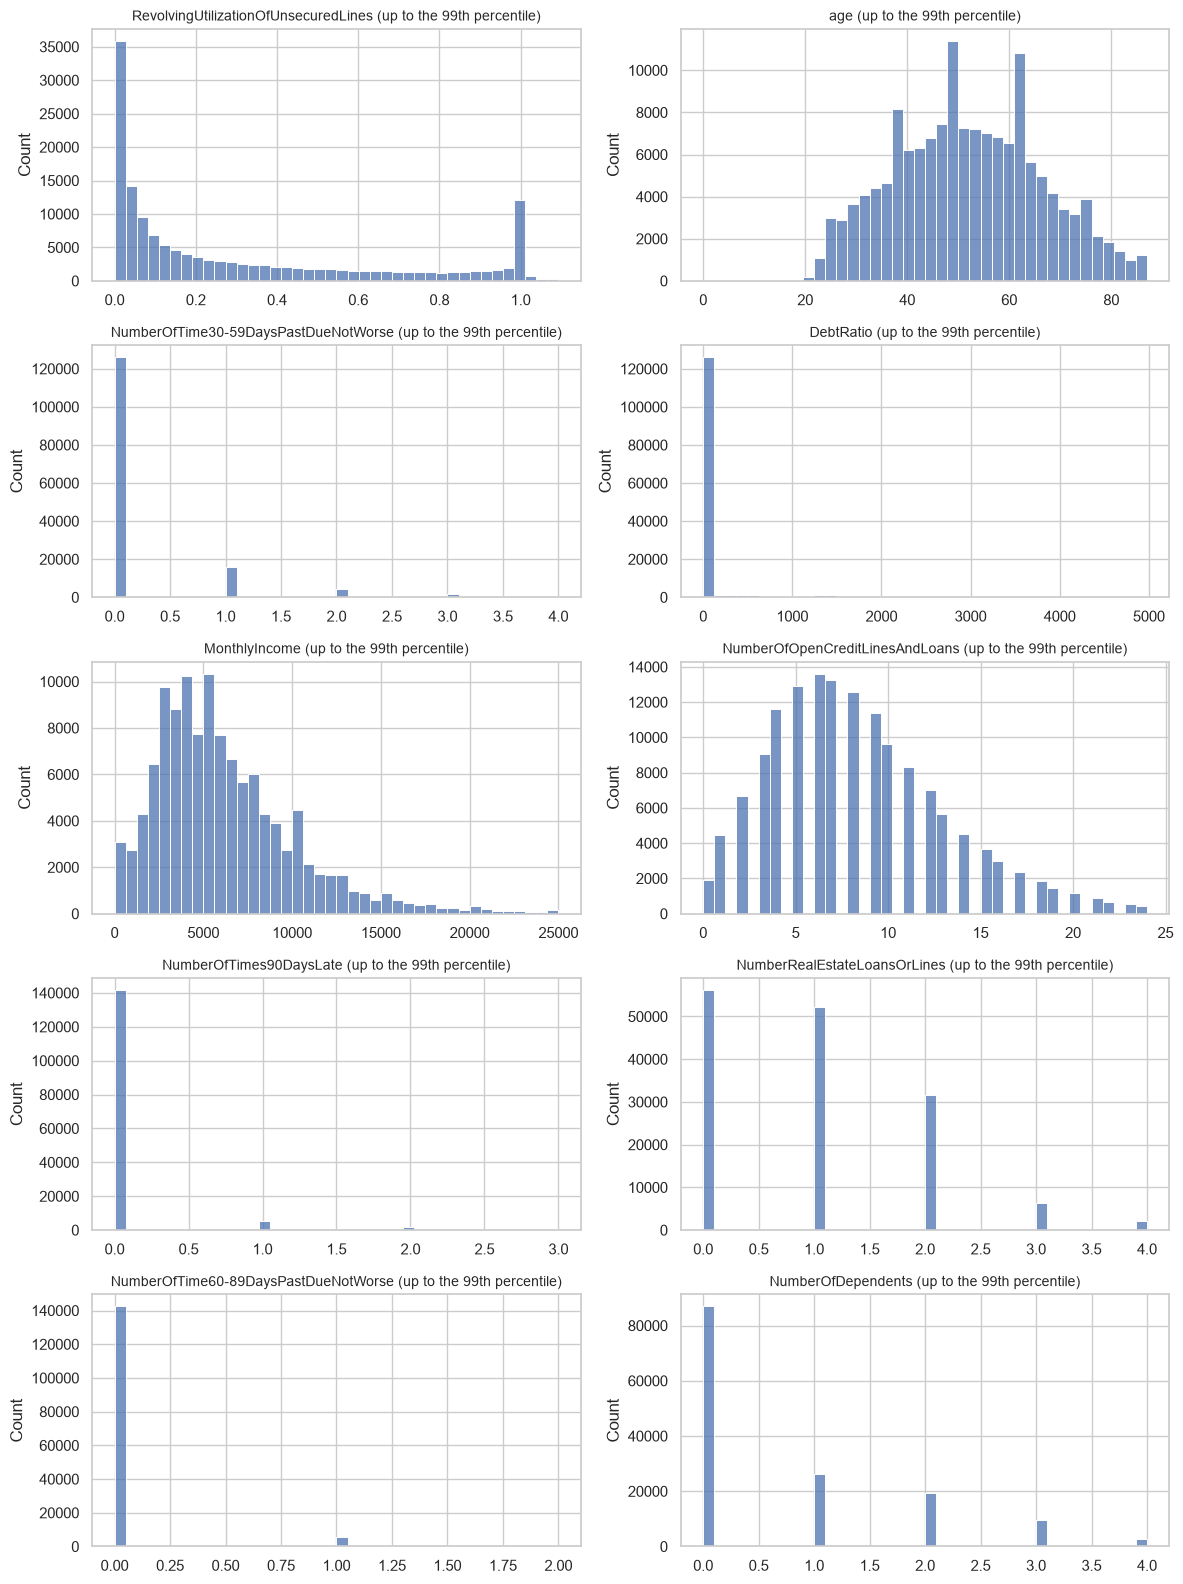

In [15]:
fig, axes = plt.subplots(5, 2, figsize=(12, 16))
for ax, col in zip(axes.ravel(), FEATURES):
    s = df[col].dropna()
    upper = s.quantile(0.99)
    sns.histplot(s[s <= upper], bins=40, ax=ax)
    ax.set_title(f"{col} (up to the 99th percentile)", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### Conclusions on distributions

- `RevolvingUtilizationOfUnsecuredLines`: the median is 0.15 and the 99th percentile 1.09, but the maximum is 50,708. The plot shows two spikes, one at 0 (no balance) and one at exactly 1 (card at its limit). Values slightly above 1 are possible, values in the thousands are not.
- `DebtRatio`: the median is 0.37 and the 99th percentile 4,979, with a maximum of 329,664. The shape of the plot does not come from a ratio with a long tail. It comes from a group of rows where the column holds large numbers, which we explain in section 4.3.
- `MonthlyIncome`: right-skewed (skewness 114), median 5,400, 99th percentile 25,000 and maximum 3,008,750. About 1,600 borrowers declare an income of exactly 0.
- The three late-payment counters have a skewness of 22 to 23 and a maximum of 98. The 98 is not a count. After removing the codes 96 and 98 (section 4.2) the skewness drops to between 4 and 9 and the maximum to between 11 and 17.
- `NumberOfOpenCreditLinesAndLoans`, `NumberRealEstateLoansOrLines` and `NumberOfDependents` are counts with a mode at a low value and a right tail. `age` is the only variable close to symmetric, with a minimum of 0 and a maximum of 109 that we check in section 4.1.

Action: no transformation here. The summary statistics are distorted by errors (codes 96 and 98, ratios that are amounts), so we first correct the errors in section 4. Extreme values that remain after that are treated in the outlier section, and the logarithm is considered after capping, because the log of an uncapped variable keeps a very long tail.

## 3. Missing values

The `isna().sum()` above shows missing values in two columns only: `MonthlyIncome` and `NumberOfDependents`. We put them as a percentage and then check whether the missingness says something about the target.

In [16]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(df) * 100).round(2)
missing[missing["n_missing"] > 0]

,n_missing,pct
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


First question: is a missing value just random noise, or does it relate to the target? We compare the default rate of borrowers with and without the value.

In [17]:
for col in ["MonthlyIncome", "NumberOfDependents"]:
    rate = df.groupby(df[col].isna())[TARGET].agg(["mean", "size"])
    rate.index = ["observed", "missing"]
    print(col)
    display(rate.round(4))

MonthlyIncome


,mean,size
observed,0.0695,120269
missing,0.0561,29731


NumberOfDependents


,mean,size
observed,0.0674,146076
missing,0.0456,3924


Second question: do the two variables go missing together?

In [18]:
pd.crosstab(
    df["MonthlyIncome"].isna(),
    df["NumberOfDependents"].isna(),
    rownames=["income missing"],
    colnames=["dependents missing"],
)

dependents missing,False,True
income missing,,
False,120269,0
True,25807,3924


Third question: do borrowers with missing income look different from the rest in the other variables?

In [19]:
income_missing = df["MonthlyIncome"].isna()
df.groupby(income_missing)[
    ["age", "DebtRatio", "RevolvingUtilizationOfUnsecuredLines", "NumberOfOpenCreditLinesAndLoans"]
].median().rename(index={False: "income observed", True: "income missing"})

,age,DebtRatio,RevolvingUtilizationOfUnsecuredLines,NumberOfOpenCreditLinesAndLoans
MonthlyIncome,,,,
income observed,51.0,0.296023,0.177282,8.0
income missing,57.0,1159.000000,0.081697,6.0


### Conclusions and decision on missing values

What the data shows:

- `MonthlyIncome` is missing in 29,731 rows (19.82%) and `NumberOfDependents` in 3,924 rows (2.62%).
- The missingness is related to the target. The default rate is 5.6% when the income is missing and 7.0% when it is observed. The groups also differ in other variables: the median age is 57 against 51, the median utilization 0.08 against 0.18, and the median number of open credit lines 6 against 8. The values are not missing at random.
- All 3,924 missing dependents fall inside the 29,731 rows with missing income. Both variables are missing together, which suggests the same origin (probably borrowers whose profile was never filled in). Within that group, the default rate is 4.6% when the dependents are missing and 5.8% when they are observed, a small difference.

Decisions:

- `MonthlyIncome`: impute with the median of the training set and add the indicator `income_missing`. The median is used because income is strongly right-skewed and the mean would be pulled up by the extreme values. The indicator keeps the information that the value was absent, which we have just seen is related to the target. Dropping the rows would remove a fifth of the file and change the population we model.
- `NumberOfDependents`: impute with the median of the training set, which is 0 and also the mode. Since the missing dependents are a subset of the missing incomes, `income_missing` already carries that information and no second indicator is added.
- Model-based imputation (KNN or iterative) is left as an option for the modelling stage. It costs more and the gain is uncertain when the missingness is concentrated in one group of borrowers.

When we reach the modelling stage the imputer is fitted on `X_train` only:

```python
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)   # medians computed on train
X_test_imp = imputer.transform(X_test)         # same medians applied to test
```

## 4. Erroneous data

### 4.1 Age

In [20]:
print("Borrowers under 18:", (df["age"] < 18).sum())
print("Borrowers over 100:", (df["age"] > 100).sum())
display(df.loc[df["age"] < 18, ["age", TARGET]])
df["age"].describe().round(1)

Borrowers under 18: 1
Borrowers over 100: 13


,age,SeriousDlqin2yrs
65695,0,0


count    150000.0
mean         52.3
std          14.8
min           0.0
25%          41.0
50%          52.0
75%          63.0
max         109.0
Name: age, dtype: float64

Conclusion: there is one borrower of age 0, which is impossible. We treat any age below 18 as an error, because a minor cannot sign a loan contract. The 13 borrowers over 100 (maximum 109) are unusual but possible, so we keep them and leave them to the outlier section.

Action: set ages below 18 to missing and impute with the training median after the split. With a single row, the effect on the model is negligible, but the value would distort the minimum of the variable.

### 4.2 Codes 96 and 98 in the late-payment counters

The three late-payment variables count events in a two-year window. We look at their largest values.

In [21]:
for col in LATE_COLS:
    print(col)
    print(df[col].value_counts().sort_index().tail(6).to_string())
    print()

NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
10      4
11      1
12      2
13      1
96      5
98    264

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
7       9
8       2
9       1
11      1
96      5
98    264

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
13      4
14      2
15      2
17      1
96      5
98    264



In [22]:
special = df[LATE_COLS].isin([96, 98])
rows_special = special.any(axis=1)

print("Rows with a 96 or 98 in some counter:", rows_special.sum())
print("Per column:", special.sum().to_dict())
print("Largest value in each counter once 96 and 98 are excluded:")
print(df[LATE_COLS].where(~special).max().to_dict())

pd.DataFrame(
    {
        "rows": [rows_special.sum(), (~rows_special).sum()],
        "default rate": [df.loc[rows_special, TARGET].mean(), df.loc[~rows_special, TARGET].mean()],
    },
    index=["with 96/98", "rest"],
).round(4)

Rows with a 96 or 98 in some counter: 269
Per column: {'NumberOfTime30-59DaysPastDueNotWorse': 269, 'NumberOfTime60-89DaysPastDueNotWorse': 269, 'NumberOfTimes90DaysLate': 269}
Largest value in each counter once 96 and 98 are excluded:
{'NumberOfTime30-59DaysPastDueNotWorse': 13.0, 'NumberOfTime60-89DaysPastDueNotWorse': 11.0, 'NumberOfTimes90DaysLate': 17.0}


,rows,default rate
with 96/98,269,0.5465
rest,149731,0.0660


In [23]:
# Do the three counters carry the code in the same rows?
df.loc[rows_special, LATE_COLS].value_counts().head()

NumberOfTime30-59DaysPastDueNotWorse  NumberOfTime60-89DaysPastDueNotWorse  NumberOfTimes90DaysLate
98                                    98                                    98                         264
96                                    96                                    96                           5
Name: count, dtype: int64

Conclusions:

- 269 rows carry a 96 (5 rows) or a 98 (264 rows), and they carry it in the three counters at the same time. Nobody has 98 late payments of 30 to 59 days in a two-year window. Once the codes are excluded, the largest values are 13, 11 and 17. The two values are codes of the data source, not counts.
- Those rows have a default rate of 54.7%, against 6.6% in the rest of the file. The code is not noise. It marks a group of borrowers that is very different from the others.

Action: replace 96 and 98 by missing values in the three counters and add a flag `late_code_flag` that marks the 269 rows, so that the information is not lost. The missing values are imputed later with the training median. If we kept the 98 as a number, it would dominate any model that uses the counters, and if we only deleted it we would throw away the strongest signal of these rows.

### 4.3 DebtRatio when income is missing

By definition `DebtRatio` is monthly debt payments divided by monthly income, so it should be a small number for most people. We check its behaviour in the two income groups.

In [24]:
income_missing = df["MonthlyIncome"].isna()

display(
    df.groupby(income_missing)["DebtRatio"]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round(2)
    .rename(index={False: "income observed", True: "income missing"})
)
display(
    (df["DebtRatio"] > 1)
    .groupby(income_missing)
    .mean()
    .round(3)
    .rename(index={False: "income observed", True: "income missing"})
    .to_frame("share with DebtRatio > 1")
)
print("Borrowers with MonthlyIncome == 0:", (df["MonthlyIncome"] == 0).sum())

# Same check for the borrowers with an income of exactly 0
display(df.loc[df["MonthlyIncome"] == 0, "DebtRatio"].describe(percentiles=[0.5, 0.9]).round(1))

,count,mean,std,min,50%,90%,99%,max
MonthlyIncome,,,,,,,,
income observed,120269.0,26.6,424.45,0.0,0.3,0.76,661.82,61106.5
income missing,29731.0,1673.4,4248.37,0.0,1159.0,3785.00,8084.50,329664.0


,share with DebtRatio > 1
MonthlyIncome,
income observed,0.060
income missing,0.939


Borrowers with MonthlyIncome == 0: 1634


count     1634.0
mean      1573.6
std       2818.0
min          0.0
50%        930.0
90%       3587.9
max      60212.0
Name: DebtRatio, dtype: float64

Conclusions:

- When the income is observed, the median `DebtRatio` is 0.30 and only 6% of the rows are above 1. When the income is missing, the median is 1,159 and 93.9% of the rows are above 1.
- The 1,634 borrowers with an income of exactly 0 behave like the missing-income group, with a median `DebtRatio` of 930. A ratio needs an income to divide by. When the income is missing or 0, the column holds an absolute amount of debt, which is not comparable with a ratio.
- That explains the `DebtRatio` histogram in section 2: one spike near 0 and a long flat tail up to 5,000. They are two different populations in the same column.

Action: set `DebtRatio` to missing wherever `MonthlyIncome` is missing or equal to 0, and impute it later with the training median. We keep `MonthlyIncome == 0` itself as it is, because a borrower can declare no income, and `income_missing` already marks the missing ones. The extreme `DebtRatio` values among borrowers with a positive income (99th percentile around 660, maximum 61,106) remain as an outlier problem for the outlier section.

### 4.4 Applying the corrections

The cell below applies the three corrections on a copy of the data, `df_fixed`, so that `df` keeps the original values for comparison. The corrections use no statistic computed from the data (they only check fixed rules), so they can be applied to the whole file before the split without leaking information. The imputation of the new missing values stays for after the split.

In [25]:
df_fixed = df.copy()

# The flags go first: once the values are replaced we could not tell
# which rows had a code or a missing income
df_fixed["late_code_flag"] = df_fixed[LATE_COLS].isin([96, 98]).any(axis=1).astype(int)
df_fixed["income_missing"] = df_fixed["MonthlyIncome"].isna().astype(int)

# Impossible age: a minor cannot hold a credit
df_fixed.loc[df_fixed["age"] < 18, "age"] = np.nan

# 96 and 98 are codes of the data source, not real counts
df_fixed[LATE_COLS] = df_fixed[LATE_COLS].where(~df_fixed[LATE_COLS].isin([96, 98]))

# Without an income (missing or 0) DebtRatio is an amount, not a ratio
no_income = df_fixed["MonthlyIncome"].isna() | (df_fixed["MonthlyIncome"] == 0)
df_fixed.loc[no_income, "DebtRatio"] = np.nan

# Quick checks that the corrections did what we wanted
assert (df_fixed["age"].dropna() >= 18).all()
assert not df_fixed[LATE_COLS].isin([96, 98]).any().any()
assert df_fixed["late_code_flag"].sum() == rows_special.sum()

nulls = pd.DataFrame(
    {
        "before": df.isna().sum().reindex(df_fixed.columns).fillna(0).astype(int),
        "after": df_fixed.isna().sum(),
    }
)
display(nulls)

# Effect of the corrections on the skewness of the problem variables
pd.DataFrame(
    {"before": df[LATE_COLS + ["DebtRatio"]].skew(), "after": df_fixed[LATE_COLS + ["DebtRatio"]].skew()}
).round(1)

,before,after
SeriousDlqin2yrs,0,0
RevolvingUtilizationOfUnsecuredLines,0,0
age,0,1
NumberOfTime30-59DaysPastDueNotWorse,0,269
DebtRatio,0,31365
MonthlyIncome,29731,29731
NumberOfOpenCreditLinesAndLoans,0,0
NumberOfTimes90DaysLate,0,269
NumberRealEstateLoansOrLines,0,0
NumberOfTime60-89DaysPastDueNotWorse,0,269


,before,after
NumberOfTime30-59DaysPastDueNotWorse,22.6,4.2
NumberOfTime60-89DaysPastDueNotWorse,23.3,7.5
NumberOfTimes90DaysLate,23.1,9.3
DebtRatio,95.2,244.4


The corrections lower the skewness of the three counters (from 23 to between 4 and 9) and leave 31,365 missing values in `DebtRatio` (29,731 without income and 1,634 with income 0). The skewness of `DebtRatio` goes up, from 95 to 244. After removing the amounts, the body of the variable has a median of 0.30, so the extreme values that remain (up to 61,106) weigh more. They do not come from the income problem and need their own treatment in the outlier section.

## 5. Summary of problems and actions

| Problem | Evidence | Action |
|---|---|---|
| `MonthlyIncome` missing (19.82%, 29,731 rows) | Default rate 5.6% when missing against 7.0% when observed; the missing group is older and uses less credit | Median imputation fitted on train after the split, plus `income_missing` |
| `NumberOfDependents` missing (2.62%, 3,924 rows) | All of them inside the missing-income rows | Median imputation (0) after the split, no extra indicator |
| Age 0 (1 row) | Impossible value | Set to missing, impute after the split |
| Codes 96 and 98 in the three late counters (269 rows) | Same rows in the three columns, maximum 13, 11 and 17 without them, default rate 54.7% against 6.6% | Set to missing, add `late_code_flag`, impute after the split |
| `DebtRatio` is an amount when income is missing or 0 (29,731 plus 1,634 rows) | Median 1,159 against 0.30; 93.9% of the missing-income rows above 1 | Set to missing, impute after the split |
| Extreme maximums in utilization, `DebtRatio` and income | Maximums of 50,708, 61,106 (with income) and 3,008,750 | Outlier treatment in the outlier section |

Next part: outliers and the relation of each variable with the target. It should start from the corrections of section 4.4, so that the outlier thresholds are not computed over values we already know are wrong.